# ProductPulse: fixture workflow
Synthetic fixture only. Change input and label together after a verified GA4 export.

In [1]:
from pathlib import Path
import pandas as pd
from productpulse.pipeline import run
root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent
output = root / 'data/processed/fixture'
run(root / 'data/fixtures/events.csv', output, 'fixture')

{'dataset_label': 'fixture',
 'input_sha256': '1e002b921d9c408e09343663a26cb6e7bd3561050352139a001f0493d83c8ddb',
 'quality': {'input_rows': 16,
  'missing_user_rows': 1,
  'missing_session_rows': 1,
  'exact_duplicate_rows': 0,
  'excluded_session_rows': 2},
 'eligible_sessions': 4,
 'date_min': '2020-11-01 00:00:00',
 'date_max': '2020-12-01 00:00:00',
 'funnel_policy': 'strict timestamps, ordered within user/session; tied timestamps do not advance',
 'pandas_version': '2.3.3'}

In [2]:
pd.read_csv(output / 'funnel.csv')

,stage,stage_order,sessions,rate_from_entry,rate_from_previous
0,page_view,1,4,1.0,1.0
1,view_item,2,4,1.0,1.0
2,add_to_cart,3,2,0.5,0.5
3,purchase,4,2,0.5,1.0


In [3]:
pd.read_csv(output / 'descriptive.csv')

,statistic,events
0,count,4.0
1,mean,3.5
2,std,1.0
3,min,2.0
4,25%,3.5
5,50%,4.0
6,75%,4.0
7,max,4.0


In [4]:
pd.read_csv(output / 'retention.csv')

,cohort_month,activity_month,month_index,cohort_users,active_users,retention_rate
0,2020-11,2020-11,0,3,3,1.000000
1,2020-11,2020-12,1,3,1,0.333333
2,2020-12,2020-12,0,1,1,1.000000


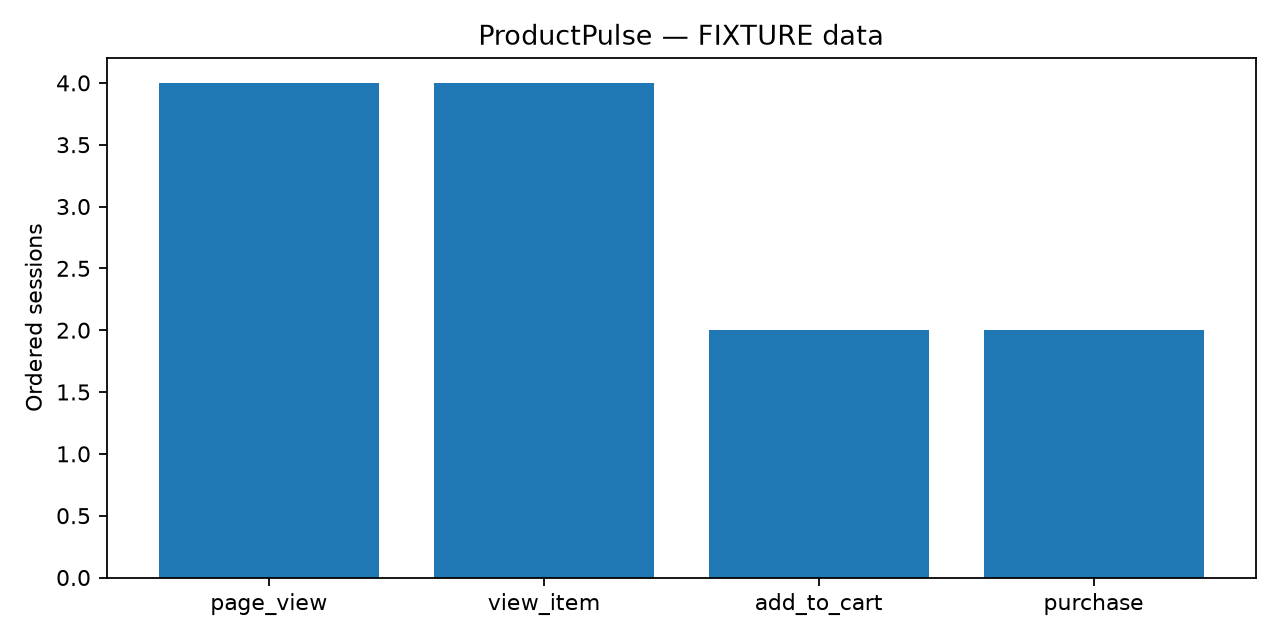

In [5]:
from IPython.display import Image, display
display(Image(filename=str(output / 'funnel.png')))